In [1]:
import pandas as pd

df = pd.read_csv(r'..\data\W158_select_nan_recode.csv')

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9593 entries, 0 to 9592
Data columns (total 29 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   QKEY                  9593 non-null   int64  
 1   F_METRO               9585 non-null   float64
 2   F_CREGION             9585 non-null   float64
 3   F_CDIVISION           9585 non-null   float64
 4   F_USR_SELFID          9493 non-null   float64
 5   F_AGECAT              9555 non-null   float64
 6   F_GENDER              9561 non-null   float64
 7   F_EDUCCAT             9572 non-null   float64
 8   F_EDUCCAT2            9572 non-null   float64
 9   F_HISP                9565 non-null   float64
 10  F_RACECMB             9449 non-null   float64
 11  F_RACETHNMOD          9491 non-null   float64
 12  F_BIRTHPLACE          9551 non-null   float64
 13  F_MARITAL             9548 non-null   float64
 14  F_RELIG               9536 non-null   float64
 15  F_PARTY_FINAL         9534 non-n

In [2]:
dep_var_list = [
    'CONF_a_W158_r',
    'CONF_b_W158_r',
    'CONF_c_W158_r',
    'CONF_d_W158_r',
    'CONF_e_W158_r',
    'CONF_i_W158_r',
    'CONF_j_W158_r'
    ]

print(dep_var_list)

['CONF_a_W158_r', 'CONF_b_W158_r', 'CONF_c_W158_r', 'CONF_d_W158_r', 'CONF_e_W158_r', 'CONF_i_W158_r', 'CONF_j_W158_r']


In [3]:
# Dependent variable labels
dep_labels = {
    'CONF_a_W158_r': 'Elected officials',
    'CONF_b_W158_r': 'Journalists',
    'CONF_c_W158_r': 'The military',
    'CONF_d_W158_r': 'Religious leaders',
    'CONF_e_W158_r': 'Business leaders',
    'CONF_i_W158_r': 'Public school principals',
    'CONF_j_W158_r': 'Police officers',
    }

print(dep_labels)

{'CONF_a_W158_r': 'Elected officials', 'CONF_b_W158_r': 'Journalists', 'CONF_c_W158_r': 'The military', 'CONF_d_W158_r': 'Religious leaders', 'CONF_e_W158_r': 'Business leaders', 'CONF_i_W158_r': 'Public school principals', 'CONF_j_W158_r': 'Police officers'}


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score


# 2. Define pipelines combining Median Imputation, Scaling, and Clustering
pipelines = {
    "K-Means": Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', KMeans(n_clusters=2, random_state=42, n_init='auto'))
    ]),
    "DBSCAN": Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', DBSCAN(eps=0.3, min_samples=5))
    ]),
    "Hierarchical": Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', AgglomerativeClustering(n_clusters=2))
    ])
}

# 3. Fit pipelines and compare results
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, pipeline) in zip(axes, pipelines.items()):
    # fit_predict fits the imputer, scales the data, and runs the clustering model
    labels = pipeline.fit_predict(X_missing)
    
    # Retrieve the processed (imputed and scaled) features for metrics & plotting
    X_processed = pipeline[:-1].transform(X_missing)
    
    # Calculate Silhouette Score (ignoring noise points labeled -1 in DBSCAN)
    non_noise_mask = labels != -1
    if len(set(labels[non_noise_mask])) > 1:
        score = silhouette_score(X_processed[non_noise_mask], labels[non_noise_mask])
        title_text = f"{name}\nSilhouette: {score:.2f}"
    else:
        title_text = name

    ax.scatter(X_processed[:, 0], X_processed[:, 1], c=labels, cmap='viridis', edgecolors='k')
    ax.set_title(title_text)
    ax.axis('off')

plt.tight_layout()
plt.show()

PCA reduced dimensions from 7 to 6.
Explained variance ratio per component: [0.374 0.225 0.104 0.09  0.077 0.067]


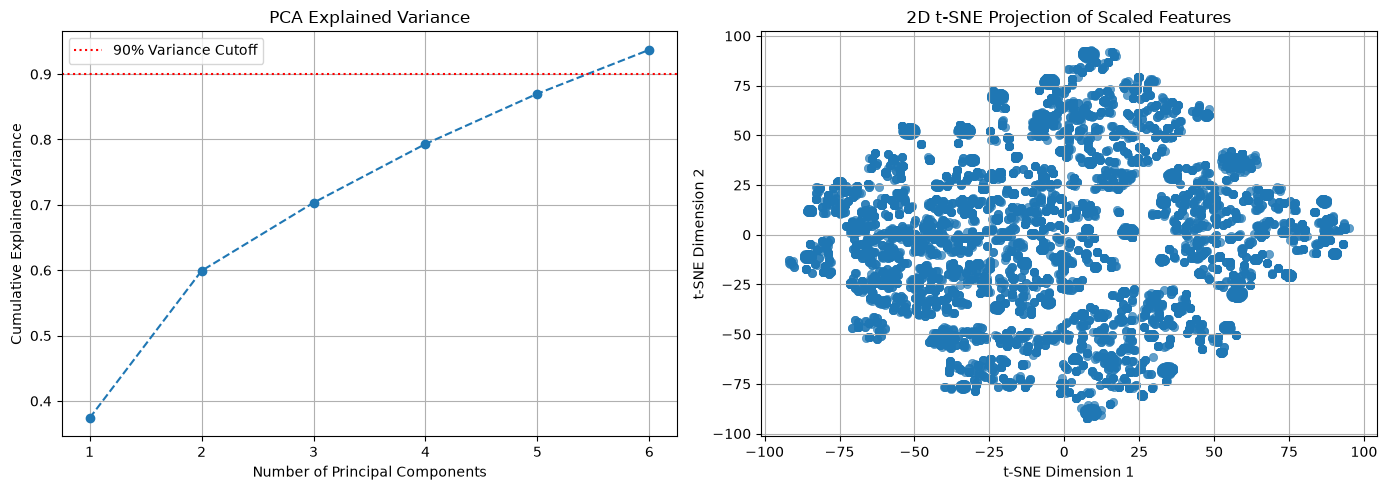

In [7]:
%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Step 1: Imputation and Scaling
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(df[dep_var_list])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# Cleaned, scaled DataFrame matching original feature names
df_scaled = pd.DataFrame(X_scaled, columns=dep_var_list, index=df.index)

# Step 2: Visual Inspection (t-SNE on scaled original features)
tsne = TSNE(
    n_components=2, perplexity=30, learning_rate="auto", random_state=42
)
X_tsne = tsne.fit_transform(X_scaled)

# Step 3: Run k-Means directly on 7 scaled features
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

# Step 4: Visualize Clusters on 2D t-SNE Projection
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=X_tsne[:, 0],
    y=X_tsne[:, 1],
    hue=df["Cluster"],
    palette="tab10",
    alpha=0.8,
)
plt.title("k-Means Clusters Visualized via 2D t-SNE Projection")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.legend(title="Cluster")
plt.grid(True)
plt.show()

# Step 5: Interpretation / Profiling (Unscaled original data)
cluster_profiles = df.groupby("Cluster")[dep_var_list].median()
print("--- Cluster Profiles (Median Values of Original Features) ---")
print(cluster_profiles)

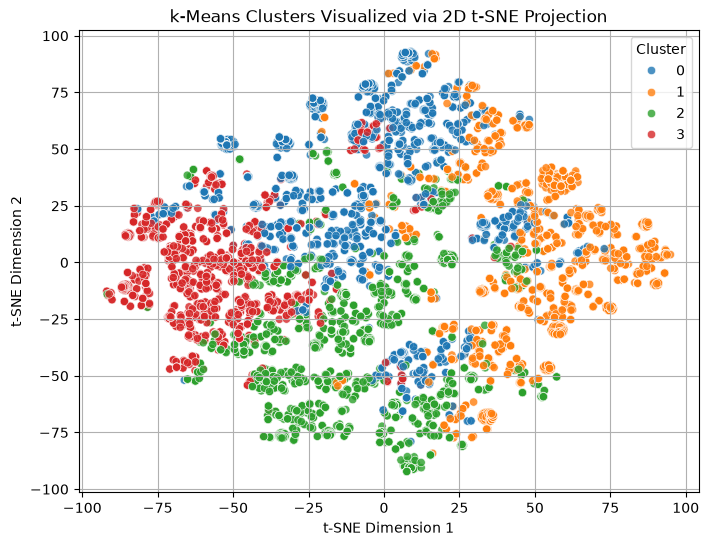

--- Cluster Profiles (Median Values of Original Features) ---
         CONF_a_W158_r  CONF_b_W158_r  CONF_c_W158_r  CONF_d_W158_r  \
Cluster                                                               
0                  2.0            3.0            3.0            2.0   
1                  3.0            3.0            4.0            3.0   
2                  2.0            2.0            3.0            3.0   
3                  2.0            2.0            2.0            2.0   

         CONF_e_W158_r  CONF_i_W158_r  CONF_j_W158_r  
Cluster                                               
0                  2.0            3.0            3.0  
1                  3.0            3.0            3.0  
2                  2.0            2.0            3.0  
3                  2.0            2.0            2.0  


In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Step 1: Imputation and Scaling
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(df[dep_var_list])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# Cleaned, scaled DataFrame matching original feature names
df_scaled = pd.DataFrame(X_scaled, columns=dep_var_list, index=df.index)

# Step 2: Visual Inspection (t-SNE on scaled original features)
tsne = TSNE(
    n_components=2, perplexity=30, learning_rate="auto", random_state=42
)
X_tsne = tsne.fit_transform(X_scaled)

# Step 3: Run k-Means directly on 7 scaled features
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

# Step 4: Visualize Clusters on 2D t-SNE Projection
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=X_tsne[:, 0],
    y=X_tsne[:, 1],
    hue=df["Cluster"],
    palette="tab10",
    alpha=0.8,
)
plt.title("k-Means Clusters Visualized via 2D t-SNE Projection")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.legend(title="Cluster")
plt.grid(True)
plt.show()

# Step 5: Interpretation / Profiling (Unscaled original data)
cluster_profiles = df.groupby("Cluster")[dep_var_list].median()
print("--- Cluster Profiles (Median Values of Original Features) ---")
print(cluster_profiles)

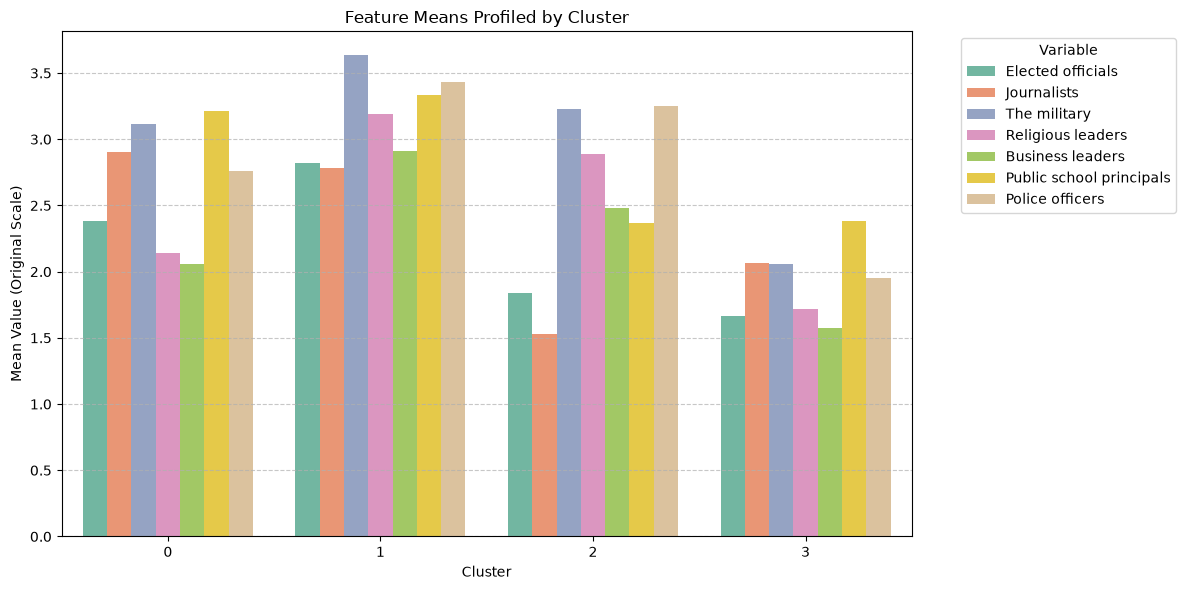

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate median feature values per cluster
cluster_profiles = df.groupby("Cluster")[dep_var_list].mean().reset_index()

# Melt DataFrame and map feature names to labels using dep_labels
df_melted = cluster_profiles.melt(
    id_vars="Cluster", var_name="Feature", value_name="Mean_Value"
)
df_melted["Feature_Label"] = df_melted["Feature"].map(
    lambda x: dep_labels.get(x, x)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=df_melted,
    x="Cluster",
    y="Mean_Value",
    hue="Feature_Label",
    palette="Set2",
)

plt.title("Feature Means Profiled by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Mean Value (Original Scale)")
plt.legend(title="Variable", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

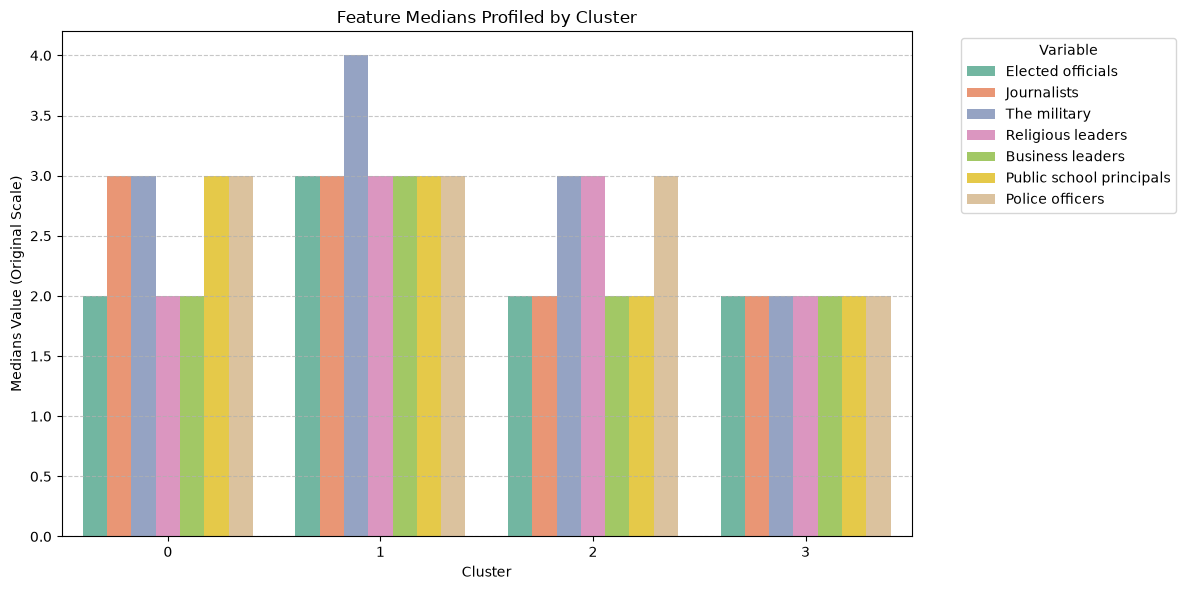

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate median feature values per cluster
cluster_profiles = df.groupby("Cluster")[dep_var_list].median().reset_index()

# Melt DataFrame and map feature names to labels using dep_labels
df_melted = cluster_profiles.melt(
    id_vars="Cluster", var_name="Feature", value_name="Median_Value"
)
df_melted["Feature_Label"] = df_melted["Feature"].map(
    lambda x: dep_labels.get(x, x)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=df_melted,
    x="Cluster",
    y="Median_Value",
    hue="Feature_Label",
    palette="Set2",
)

plt.title("Feature Medians Profiled by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Medians Value (Original Scale)")
plt.legend(title="Variable", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

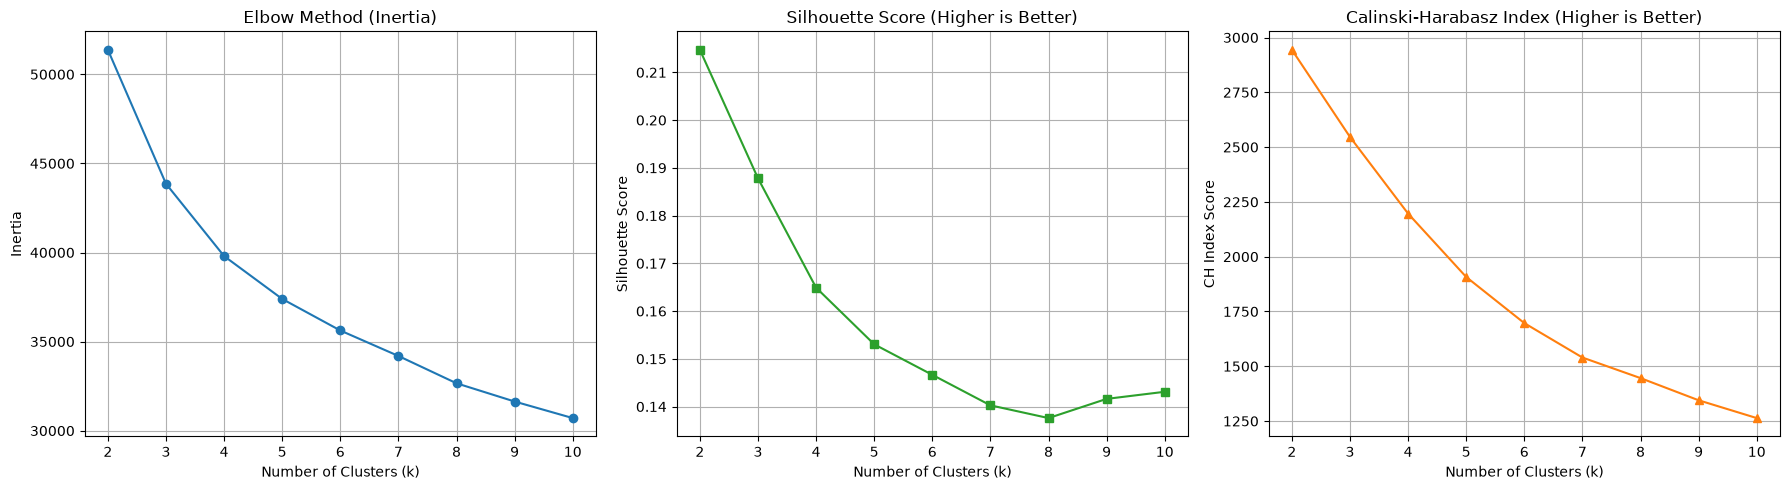

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score, silhouette_score

# Range of k to test
k_range = range(2, 11)

inertia_list = []
silhouette_list = []
ch_list = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    inertia_list.append(kmeans.inertia_)
    silhouette_list.append(silhouette_score(X_scaled, labels))
    ch_list.append(calinski_harabasz_score(X_scaled, labels))

# Plotting the metrics side-by-side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Elbow Plot (Inertia)
axes[0].plot(k_range, inertia_list, marker="o", color="tab:blue")
axes[0].set_title("Elbow Method (Inertia)")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(k_range)
axes[0].grid(True)

# 2. Silhouette Score Plot
axes[1].plot(k_range, silhouette_list, marker="s", color="tab:green")
axes[1].set_title("Silhouette Score (Higher is Better)")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(k_range)
axes[1].grid(True)

# 3. Calinski-Harabasz Score Plot
axes[2].plot(k_range, ch_list, marker="^", color="tab:orange")
axes[2].set_title("Calinski-Harabasz Index (Higher is Better)")
axes[2].set_xlabel("Number of Clusters (k)")
axes[2].set_ylabel("CH Index Score")
axes[2].set_xticks(k_range)
axes[2].grid(True)

plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Select relevant columns
df_subset = df[dep_var_list].copy()

# Step 1: Replace special response code 99 with NaN
df_subset = df_subset.replace(99, np.nan)

# Step 2: Handle missing values via median imputation
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(df_subset)

# Step 3: Standardize features (Mean = 0, Variance = 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# Step 4: Baseline Analysis — Elbow Method to determine optimal k
inertia = []
k_range = range(1, 10)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Step 5: Plot the Elbow Curve
plt.figure(figsize=(8, 4))
plt.plot(k_range, inertia, marker="o")
plt.title("Elbow Method for Optimal k")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia (Sum of Squared Errors)")
plt.grid(True)
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score

# 2. Define pipelines combining Median Imputation, Scaling, and Clustering
pipelines = {
    "K-Means": Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', KMeans(n_clusters=2, random_state=42, n_init='auto'))
    ]),
    "DBSCAN": Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', DBSCAN(eps=0.3, min_samples=5))
    ]),
    "Hierarchical": Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', AgglomerativeClustering(n_clusters=2))
    ])
}

# 3. Fit pipelines and compare results
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, pipeline) in zip(axes, pipelines.items()):
    # fit_predict fits the imputer, scales the data, and runs the clustering model
    labels = pipeline.fit_predict(X_missing)
    
    # Retrieve the processed (imputed and scaled) features for metrics & plotting
    X_processed = pipeline[:-1].transform(X_missing)
    
    # Calculate Silhouette Score (ignoring noise points labeled -1 in DBSCAN)
    non_noise_mask = labels != -1
    if len(set(labels[non_noise_mask])) > 1:
        score = silhouette_score(X_processed[non_noise_mask], labels[non_noise_mask])
        title_text = f"{name}\nSilhouette: {score:.2f}"
    else:
        title_text = name

    ax.scatter(X_processed[:, 0], X_processed[:, 1], c=labels, cmap='viridis', edgecolors='k')
    ax.set_title(title_text)
    ax.axis('off')

plt.tight_layout()
plt.show()